### EDA

In [9]:
from wilds import get_dataset
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns

### Loads the dataset and splits the data

In [ ]:
#SSL-CERTIFICATE has expired need to download dataset manually.

#Need to perform this operation to load dataset in current pandas version
pd.options.future.infer_string = False


dataset = get_dataset(dataset="civilcomments", download=False)

train_data = dataset.get_subset("train")
val_data = dataset.get_subset("val")
test_data = dataset.get_subset("test")

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

Train: 269038
Validation: 45180
Test: 133782


### Dataset description
- id: UserID to person who target or referance- commen. Dtype: int64
- comment_text: Comments target or referance- by users Dtype: object
- split: train, test, val.
- created_date: Date when the comments were create. Dtype: Object
- publication_id: my assumption is where the publication was published
- parent_id: No idea
- article_id: ID for which article the comment was extracted from dtype: int64
- rating: Decides if the comment was approved or rejected. Dtype: object
- funny: Binary where comments are either maarked as funny or not (1, 0) dtype: int64
- wow: Binary where comments are either marked with wow or not (1, 0) dtype: int64
- sad: Binary where comment is either marked as sad or not (1, 0) dtype: int64
- likes: Count of likes for the comment dtype int 64
- disagree: Count of disagrees for the comment dtype: int64
- toxicity: continious value from [0, 1] with toxicity level of comment dtype: float64
- severe_toxicity: continious value from [0, 1] with severe toxicity level of comment. dtype: float64
- obscene: continious value from [0,1] with obscenity of a comment. dtype: float64
- sexual_explicit: Continious value from [0,1] with how sexual a comment is. dtype: float64
- identity_attack: Continious value from [0,1] with identity attack. dtype: float64
- insult: Continious value from [0,1] with how much insult a comment has. dtype: float64
- threat: Continious value from [0,1] with how much threat the comment has. dtype: float64
- male: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a male. dtype: float64
- femaile: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a female. dtype: float64
- transgender: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a transgender. dtype: float64
- other_gender: Continious value from [0,1] with how sure annotators are that the comment is target or referance by other gender. dtype: float64
- heterosexual: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a heterosexual. dtype: float64
- homosexual_gay_or_lesbian: Continious value from [0,1] with how sure annotators are that the comment is target or referance by homosexual gay or lesbian. dtype: float64
- bisexual: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a bisexual. dtype: float64
- other_sexual_orientation: Continious value from [0,1] with how sure annotators are that the comment is target or referance by other sexual orientation. dtype: float64
- christian: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a christian. dtype: float64
- jewish: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a jewish. dtype: float64
- muslim: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a muslim. dtype: float64
- hindu: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a hindu. dtype: float64
- buddhist: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a buddhist. dtype: float64
- atheist: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a atheist. dtype: float64
- other_religion: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a other religion. dtype: float64
- black: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a black person. dtype: float64
- white: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a white person. dtype: float64
- asian: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a asian person. dtype: float64
- latino: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a latino person. dtype: float64
- other_race_or_ethnicity: Continious value from [0,1] with how sure annotators are that the comment is target or referance by a other race or ethnicity. dtype: float64
- physical_disability: Continious value from [0,1] with how sure annotators are that the comment targets or references someone with physical disability . dtype: float64
- intellectual_or_learning_disability: Continious value from [0,1] with how sure annotators are that the comment targets or references someone with intellectual_or_learning_disability . dtype: float64
- intellectual_or_learning_disability: Continious value from [0,1] with how sure annotators are that the comment targets or references someone with intellectual_or_learning_disability . dtype: float64
- other_disability: Continious value from [0,1] with how sure annotators are that the comment targets or references someone with other_disability . dtype: float64
- identity_anotator_count: Count of how many anotators revivewed a specific comment to determine if it targets any identity groups dtype: int64
- toxicitiy_anotator_count: Count of how many anotators revivewed a specific comment to determine if it is toxic. dtype: int64
- LGBTQ: Binary if the comment is attacking or referenceing LGBTQ group. dtype: int64
- other_religions: Binary if the comment is attacking or referencing another relgion. dtype: int64
- asian_latino_etc: Binary if the comment is attacking or referencing another asian_latino_etc. dtype: int64
- disability_any: Binary if the comment is attacking or referencing a disability. dtype: int64
- num_identities: count of how many identities. dtype: float64
- more_then_one_identity: bool true if more then one identity else false. dtype: bool
- na_gender: count if gender is not mentioned. dtype: int64
- na_orientation: count if orientation is not mentioned. dtype: int64
- na_religion: count if relgiion is not mentioned. dtype: int64
- na_race: count if race is not mentioned dtype: int64
- na_disability: count if disability is not mentioned: int64















### Converts the training set into a pandas dataframe for data inspection. And gets target variables from Wilds

In [ ]:
train_df = dataset._metadata_df.iloc[train_data.indices].copy() #Method to only view the training data in pandas

train_df["label"] = train_data.y_array.numpy()

## Values and plot for class distribution of target variable

In [21]:
train_df["label"].value_counts().sort_index()

label
0    238523
1     30515
Name: count, dtype: int64

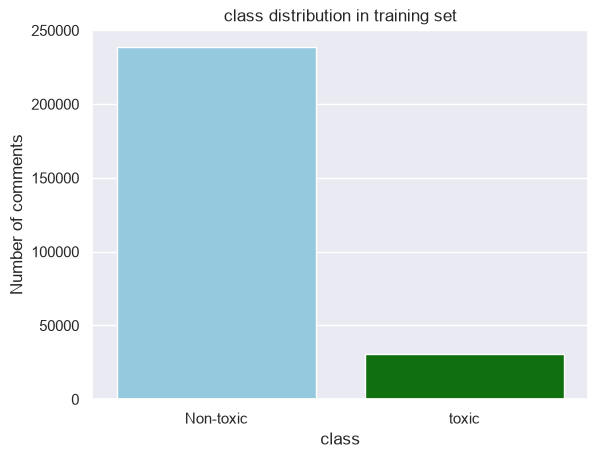

In [ ]:
sns.set_theme()

sns.countplot(
    data=train_df,
    x="label",
    hue="label",
    palette={0: "skyblue", 1: "green"},
    legend=False
)

plt.xticks([0,1], ["Non-toxic", "toxic"])
plt.xlabel("class")
plt.ylabel("Number of comments")
plt.title("class distribution in training set")
plt.show()

## Using same identity columns as WILDS.

In [26]:
identity_cols = [
    "male", "female", "LGBTQ",
    "christian", "muslim", "other_religions",
    "black", "white"
]

results = []

for identity in identity_cols:
    group = train_df[train_df[identity] >= 0.5]
    
    results.append({
        'Identity': identity,
        'Non-toxic': (group["label"] == 0).sum(),
        'Toxic': (group["label"] == 1).sum()
    })
    
identity_df = pd.DataFrame(results)
    

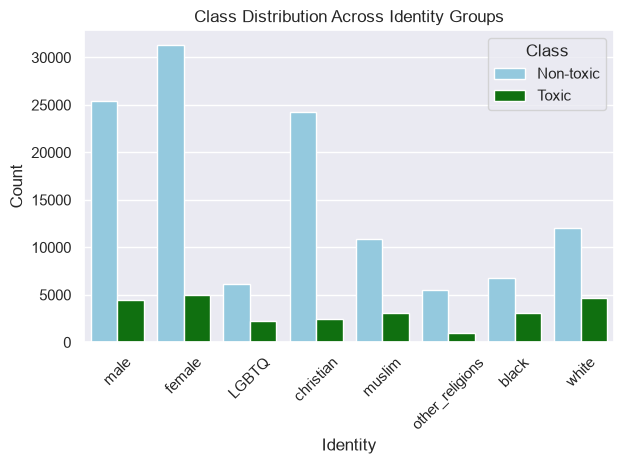

In [28]:
plot_df = identity_df.melt(
    id_vars="Identity",
    var_name="Class",
    value_name="Count",
)

sns.barplot(
    data=plot_df,
    x="Identity",
    y="Count",
    hue="Class",
    palette={"Non-toxic": "skyblue", "Toxic": "green"}
)

plt.xticks(rotation=45)
plt.title("Class Distribution Across Identity Groups")
plt.tight_layout()
plt.show()

In [29]:
distribution_df = identity_df.copy()

distribution_df["Total"] = (
    distribution_df["Non-toxic"] + distribution_df["Toxic"]
)

distribution_df["toxic_pct"] = (
    distribution_df["Toxic"] / distribution_df["Total"] * 100
)

print(distribution_df)

          Identity  Non-toxic  Toxic  Total  toxic_pct
0             male      25373   4437  29810  14.884267
1           female      31282   4962  36244  13.690542
2            LGBTQ       6155   2265   8420  26.900238
3        christian      24292   2446  26738   9.148029
4           muslim      10829   3125  13954  22.395012
5  other_religions       5541   1003   6544  15.327017
6            black       6785   3111   9896  31.436944
7            white      12016   4682  16698  28.039286


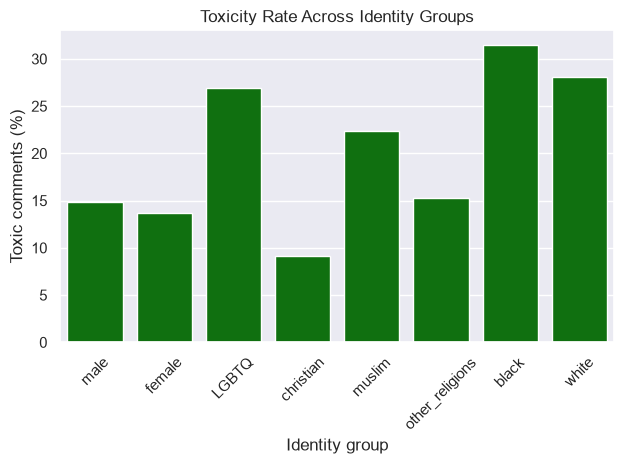

In [30]:
sns.barplot(
    data=distribution_df,
    x="Identity",
    y="toxic_pct",
    color="green"
)

plt.xticks(rotation=45)
plt.xlabel("Identity group")
plt.ylabel("Toxic comments (%)")
plt.title("Toxicity Rate Across Identity Groups")
plt.tight_layout()
plt.show()

In [31]:
results = []

for identity in identity_cols:
    mentioned = train_df[identity] >= 0.5

    for group_name, mask in [
        ("Mentioned", mentioned),
        ("Not mentioned", ~mentioned)
    ]:
        subset = train_df.loc[mask]

        results.append({
            "identity": identity,
            "group": group_name,
            "count": len(subset),
            "toxic_pct": subset["label"].mean() * 100
        })

distribution2_df = pd.DataFrame(results)

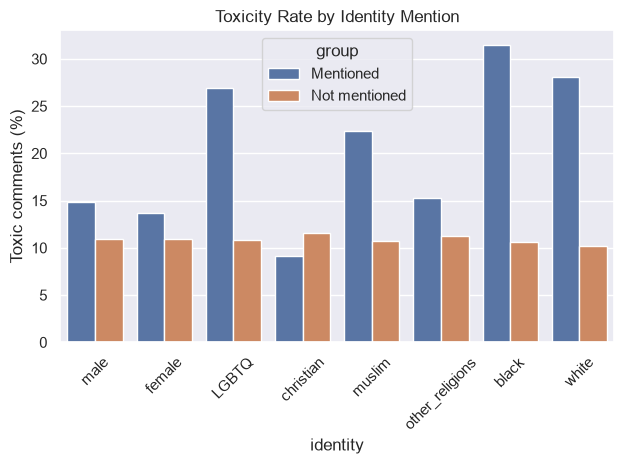

In [32]:
sns.barplot(
    data=distribution2_df,
    x="identity",
    y="toxic_pct",
    hue="group"
)

plt.xticks(rotation=45)
plt.ylabel("Toxic comments (%)")
plt.title("Toxicity Rate by Identity Mention")
plt.tight_layout()
plt.show()

### Sequence length

In [33]:
train_df["word_count"] = (
    train_df["comment_text"].fillna("")
    .str.split()
    .str.len()
)

train_df["word_count"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    269038.000000
mean         60.703860
std          49.703993
min           0.000000
25%          21.000000
50%          45.000000
75%          88.000000
90%         148.000000
95%         166.000000
99%         181.000000
max         315.000000
Name: word_count, dtype: float64

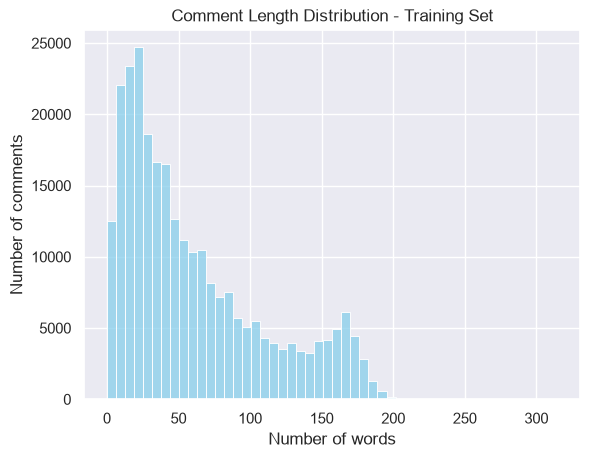

In [34]:
sns.histplot(
    data=train_df,
    x="word_count",
    bins=50,
    color="skyblue"
)

plt.xlabel("Number of words")
plt.ylabel("Number of comments")
plt.title("Comment Length Distribution - Training Set")
plt.show()

## TODO

1. We need to find length of token using a BERT model, I have not decided yet for which model to look at.
2. Metrics for binary classification needs to be implemented + evaulation
3. Train BERT model using ERM (standard /baseline) / transfer learning or with pre trained
4. Train BERT model using group DRO 
